In [133]:
from basic_packages import *

In [134]:
#Reskin of HW0 Finite difference code. 
#Except this time we will put everything inside defined functions for ease of use.

def make_grid(a, b, N):
    lnspc = np.linspace(a, b, N+1)
    return np.row_stack((lnspc, lnspc))

def get_interior_index(i, j, N):    
    assert 1 <= i < N
    assert 1 <= j < N
    return (i-1)*(N-1) + (j-1)

def get_boundary_index(i, j, N):
    assert i == 0 or i == N or j == 0 or j == N, "Point is not on the boundary"
    if i == 0:
        return j  # Top boundary
    if i == N:
        return N + j + 1  # Bottom boundary
    if j == 0:
        return 2*N + i + 1 # Left boundary
    if j == N:
        return 3*N + i # Right boundary

def populate_A(A, N):
    for i in range(1, N):
        for j in range(1, N):
            A[get_interior_index(i, j, N), get_interior_index(i, j, N)] = -4    #Self-reference term
            if i > 1:
                A[get_interior_index(i, j, N), get_interior_index(i-1, j, N)] = 1 #Above neighbor compressed to row-major order
            if i < N-1:
                A[get_interior_index(i, j, N), get_interior_index(i+1, j, N)] = 1 #Below neighbor compressed to row-major order
            if j > 1:
                A[get_interior_index(i, j, N), get_interior_index(i, j-1, N)] = 1 #Left neighbor compressed to row-major order
            if j < N-1:
                A[get_interior_index(i, j, N), get_interior_index(i, j+1, N)] = 1 #Right neighbor compressed to row-major order
    return A

def populate_B_bd(B_bd, N):
    for i in range(1, N):
        for j in range(1, N):
            if i == 1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i-1, j, N)] = 1 #Top boundary compressed to row-major order. Note that the index of the boundary matrix is offset from the interior point matrix. 
            if i == N-1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i+1, j, N)] = 1 #Bottom boundary compressed to row-major order.
            if j == 1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i, j-1, N)] = 1 #Left boundary compressed to row-major order.
            if j == N-1:
                B_bd[(i-1)*(N-1) + (j-1), get_boundary_index(i, j+1, N)] = 1 #Right boundary compressed to row-major order.
    return B_bd

def make_A(N, h):
    A = sp.sparse.lil_matrix(((N-1)**2, (N-1)**2))
    A = populate_A(A, N)
    return A.tocsr() * (1/h**2)

def make_B_bd(N, h):
    B_bd = sp.sparse.lil_matrix(((N-1)**2, 4*N))
    B_bd = populate_B_bd(B_bd, N)
    return B_bd.tocsr() * (1/h**2)

def make_u_bd(N, u, x):
    u_bd = np.zeros(4*N)
    for i in range(N+1):
        for j in range(N+1):
            if i == 0 or i == N or j == 0 or j == N:
                u_bd[get_boundary_index(i, j, N)] = u((x[0][i], x[1][j]))
    return u_bd

def make_f_vec(N, f, x):
    f_vec = np.zeros((N-1)**2)
    for i in range(1, N):
        for j in range(1, N):
            f_vec[get_interior_index(i, j, N)] = f((x[0][i], x[1][j]))
    return f_vec

def make_rhs(f_vec, B_bd, u_bd):
    return f_vec - B_bd @ u_bd

def full_system(N, a, b, u, f):
    h = (b-a) / N
    x = make_grid(a, b, N)
    A = make_A(N, h)
    B_bd = make_B_bd(N, h)
    u_bd = make_u_bd(N, u, x)
    f_vec = make_f_vec(N, f, x)
    b = make_rhs(f_vec, B_bd, u_bd)
    u_approx = sp.sparse.linalg.spsolve(A, b)
    return u_approx

def get_exact(N, a, b, u):
    x = make_grid(a, b, N)
    u_exact = np.zeros((N-1)**2)
    for i in range(1, N):
        for j in range(1, N):
            u_exact[get_interior_index(i, j, N)] = u((x[0][i], x[1][j]))
    return u_exact

def get_boundary_values(x):
    X, Y = np.meshgrid(x[0], x[1], indexing='ij')

    # Extract all four edges
    boundary_mask = np.zeros(X.shape, dtype=bool)
    boundary_mask[[0, -1], :] = True
    boundary_mask[:, [0, -1]] = True

    # Return coordinates in your preferred (2, M) format
    x_boundary = np.array([X[boundary_mask], Y[boundary_mask]])
    return x_boundary

**Problem 1.** Solving $\nabla ^2 u = f(x,y)$ on $x \in [0,2\pi ], \, y \in [0, 2\pi ]$ with Dirichelet boundary conditions on all sides. We use our code from HW0 to accomplish this.

C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


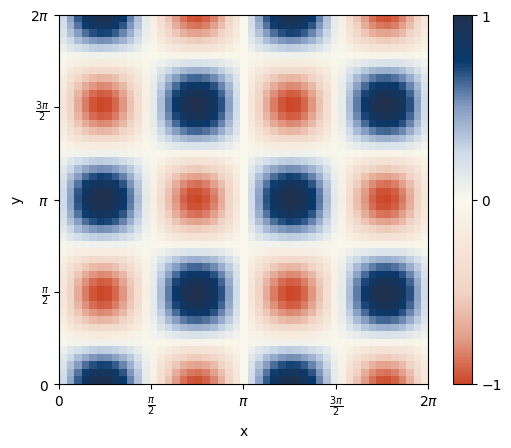

C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


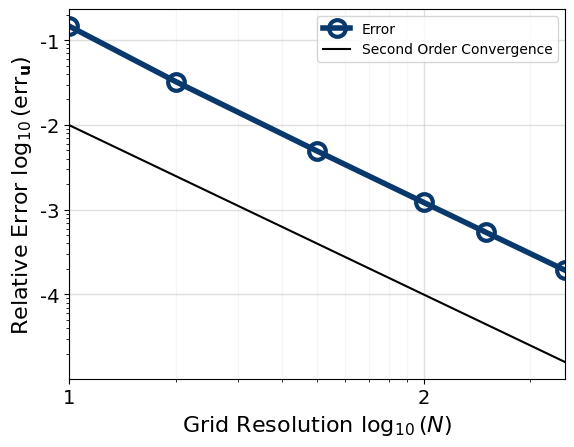

In [135]:
#Here we will only use this cell to implement the functions above.

N = 50
a = 0
b = 2 * np.pi



def u(x):
    return np.cos(2*x[0]) * np.sin(2*x[1])

def f(x):
    return -8 * np.cos(2*x[0]) * np.sin(2*x[1])

xy_ticks = np.arange(0, 2*np.pi + 0.01, np.pi/2)
xy_labels = [
    r'$0$',
    r'$\frac{\pi}{2}$',
    r'$\pi$',
    r'$\frac{3\pi}{2}$',
    r'$2\pi$'
]

u_approx = full_system(N, a, b, u, f)

fig, ax = plt.subplots()
im = ax.imshow(u_approx.reshape((N-1, N-1)), extent=(a, b, a, b), origin='lower', cmap=mines_cmap_div)
cbar = fig.colorbar(im, ax=ax)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xticks(xy_ticks)
ax.set_xticklabels(xy_labels)
ax.set_yticks(xy_ticks)
ax.set_yticklabels(xy_labels)
cbar.set_ticks([-1, 0, 1])
plt.savefig('u_approx.pdf', bbox_inches='tight')
plt.show()


N_vals = [10, 20, 50, 100, 150, 250]
errors = []
Order_2 = [(1 / N**2) for N in N_vals]

for N in N_vals:
    u_approx = full_system(N, a, b, u, f)
    u_exact = get_exact(N, a, b, u)
    errors.append(np.linalg.norm(u_approx - u_exact) / np.linalg.norm(u_exact))

plt.loglog(N_vals, errors, marker='o', color=blaster_blue, linewidth=4, markersize=12, markeredgewidth=3, markerfacecolor='none', label='Error')
plt.loglog(N_vals, Order_2,  color='black',  label='Second Order Convergence')
plt.legend()
plt.ylabel(r"Relative Error $\log_{10}(\text{err}_\mathbf{u})$", fontsize=16)
plt.xlabel(r"Grid Resolution $\log_{10}(N)$", fontsize=16)
plt.xlim([min(N_vals), max(N_vals)])
plt.grid(True, which="major", linewidth=1, alpha=0.5, color='silver')
plt.grid(True, which="minor", linewidth=1, alpha=0.15, color='silver')
plt.grid(False, axis="y", which="minor")
plt.xticks([10, 100], ['1', '2'], fontsize=14)
plt.yticks([1e-1, 1e-2, 1e-3, 1e-4], ['-1', '-2', '-3', '-4'], fontsize=14)
plt.savefig("HW0_Dirichilet_Convergence.pdf", bbox_inches='tight')
plt.show()

Consider the same setup as in Problem 1, but with an additional Dirichilet Condition:

$$\begin{aligned}
    u(x^{ib}, y^{ib}) = cos(2x^{ib})sin(wy^{ib}), \qquad&(1) \\
    x^{ib} = \pi + \cos(\theta). \, y^{ib} = \pi + \sin(\theta), \, \theta \in [0, 2\pi]. \qquad &(2)
\end{aligned}$$

Since this is saying that it is the test function $u$ (where the interior already should have been u) on the boundary, this is going to have the same test solution.

**1.** Discretize $(x^{ib}, y^{ib})$ using $N_{ib}$ points so that the spacing between these IB points is roughly the same as the $\Delta x$ from the finite difference grid:

In [136]:
def x_param(th):
    return np.pi + np.cos(th)

def y_param(th):
    return np.pi + np.sin(th)

def get_boundary_points(a, b, N, x_param, y_param):
    th_values = np.linspace(a, b, N)
    x_points = x_param(th_values)
    y_points = y_param(th_values)
    return np.array([x_points, y_points])

In [137]:
a_th = 0
b_th = 2 * np.pi
N = 50

bd_x = get_boundary_points(a_th, b_th, N, x_param, y_param)
bd_x.shape

(2, 50)

**2.** Now imagine we placed a charge $q_k$ on each IB point $(x_k^{ib}, y_k^{ib})$. We want to *solve* for those chyarges so that the internal boundary contition is maintained.

$$
\nabla^2 u = f(x,y) + \sum_{k=1}^{N_{ib}} q_k \delta_a (x - x_k^{ib}, y - y_k^{ib}) = f(x,y) + \mathcal{S}^{ib}(q),
$$

where we've introduced the compact notation $\mathcal{S}$ for the *spreading* operation involving regularized delta functions $\delta_a$. **For this assignment, take $\delta_a$ to be a 2D Gaussian with variance $a = 1.2 \Delta x$. This is what's used in the example code on Canvas.**



In [138]:
def delta_a(x, y, a):
    exp_term = np.exp(-(x**2 + y**2)/(2 * a**2))
    return exp_term / (2 * np.pi * a**2)

def get_S_ib(x_vals, a, x_ib_vals):
    N = x_vals.shape[1]-1
    N_ib = x_ib_vals.shape[1]
    S_ib = np.zeros(((N-1)**2, N_ib))
    for i in range(1, N):
        for j in range(1, N):
            for k in range(N_ib):
                x = [x_vals[0, i], x_vals[1, j]]
                x_ib = x_ib_vals[:, k]
                S_ib[get_interior_index(i, j, N), k] = delta_a(x[0]-x_ib[0], x[1]-x_ib[1], a)
    return S_ib


In [139]:
N = 50
a = 0
b = 2 * np.pi
h = (b - a) / N
reg_var = 1.2*h

x_vals = make_grid(a, b, N)
x_ib_vals = get_boundary_points(a, b, N, x_param, y_param)
S_ib = get_S_ib(x_vals, reg_var, x_ib_vals)

S_ib[1000]

C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


array([7.41678387e-24, 5.26512700e-25, 5.61173880e-26, 9.31637026e-27,
       2.48120047e-27, 1.08337163e-27, 7.86145345e-28, 9.53070224e-28,
       1.92429013e-27, 6.39630721e-27, 3.43190745e-26, 2.89140678e-25,
       3.69362079e-24, 6.86117940e-23, 1.76649551e-21, 5.97626314e-20,
       2.50748851e-18, 1.22713905e-16, 6.57128188e-15, 3.60679771e-13,
       1.89997009e-11, 9.00027952e-10, 3.59863394e-08, 1.14311239e-06,
       2.72551001e-05, 4.63018162e-04, 5.34983802e-03, 4.03854937e-02,
       1.92680371e-01, 5.66283718e-01, 1.00722715e+00, 1.07401659e+00,
       6.85846512e-01, 2.64224813e-01, 6.23810982e-02, 9.24185612e-03,
       8.86562057e-04, 5.72293987e-05, 2.60034263e-06, 8.74960776e-08,
       2.30505090e-09, 5.04706124e-11, 9.77944089e-13, 1.78908001e-14,
       3.30003474e-16, 6.55321372e-18, 1.49411860e-19, 4.16172577e-21,
       1.50194624e-22, 7.41678387e-24])

**3.** If we discretize our new PDE
$$
\nabla^2 u = f(x,y) + \mathcal{S}^{ib}(q)
$$
directly, we'll have too many unknowns($u(x_i, y_j)$, and $q$) for the equations we have. We can fix this by *interpolating $u$* onto the IB grid and enforcing our internal boundary condition.

$$
\int \int_{(x,y)} u(x,y) \delta_a(x-x_k^{ib}, y-y_k^{ib}) dx dy = \mathcal{J}^{ib}(u) = \cos(2x^{ib})\sin(2y^{ib})
$$

In [140]:
# def get_J_ib(u_approx, N, x_vals, x_ib_vals, delta_a, reg_var, h):
#     J_val = np.zeros(x_ib_vals.shape[1])
#     for k in range(x_ib_vals.shape[1]):
#         x_ib = x_ib_vals[:, k]
#         for i in range(1, N):
#             for j in range(1, N):
#                 x = [x_vals[0, i], x_vals[1, j]]
#                 J_val[k] += u_approx[get_interior_index(i, j, N)] * delta_a(x[0]-x_ib[0], x[1]-x_ib[1], reg_var)
#     return J_val * (h**2)

def get_immersed_boundary_u(u, N_bd, x_ib_vals):
    u_ib = np.zeros(N_bd)
    for k in range(N_bd):
        u_ib[k] = u([x_ib_vals[0, k], x_ib_vals[1, k]])
    return u_ib

def get_J_ib_fast(u_approx, S_ib, h):
    return h**2 * (S_ib.T @ u_approx)

In [141]:
#Create a test 

N=100
N_ib = 50
a = 0
b = np.pi * 2
h = (b - a) / N
reg_var = 1.2*h
x_vals = make_grid(a, b, N)
x_ib_vals = get_boundary_points(a, b, N_ib, x_param, y_param)
S_ib = get_S_ib(x_vals, reg_var, x_ib_vals)

u_test = get_exact(N, a, b, u)

J_ib = get_J_ib_fast(u_test, S_ib, h)
u_ib = get_immersed_boundary_u(u, x_ib_vals.shape[1], x_ib_vals)

[J_ib, u_ib]


C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


[array([ 3.80958733e-17, -9.92020968e-02, -1.68981337e-01, -1.86190192e-01,
        -1.38952848e-01, -2.91347929e-02,  1.28592024e-01,  3.11025521e-01,
         4.92713939e-01,  6.51980259e-01,  7.74518308e-01,  8.53578373e-01,
         8.87444775e-01,  8.76165860e-01,  8.19667936e-01,  7.18419013e-01,
         5.76235656e-01,  4.03464298e-01,  2.18336351e-01,  4.50589972e-02,
        -9.12138716e-02, -1.70839588e-01, -1.85207590e-01, -1.39431337e-01,
        -5.15166042e-02,  5.15166042e-02,  1.39431337e-01,  1.85207590e-01,
         1.70839588e-01,  9.12138716e-02, -4.50589972e-02, -2.18336351e-01,
        -4.03464298e-01, -5.76235656e-01, -7.18419013e-01, -8.19667936e-01,
        -8.76165860e-01, -8.87444775e-01, -8.53578373e-01, -7.74518308e-01,
        -6.51980259e-01, -4.92713939e-01, -3.11025521e-01, -1.28592024e-01,
         2.91347929e-02,  1.38952848e-01,  1.86190192e-01,  1.68981337e-01,
         9.92020968e-02,  4.02801396e-16]),
 array([ 1.01926578e-16, -1.01483753e-01, -1

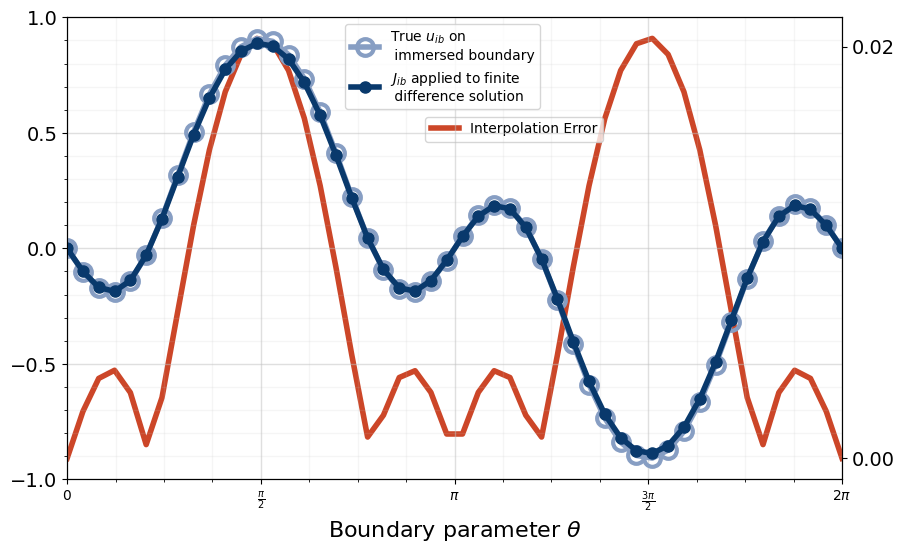

In [142]:
#Plot J_ib, u_ib, and their difference on one plot.
th_vals = np.linspace(0, 2*np.pi, len(u_ib))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(th_vals, u_ib, label=r'True $u_{ib}$ on' + '\n immersed boundary', color=light_blue, linewidth=4, marker='o', markersize=12, markeredgewidth=3, markerfacecolor='none')
ax.plot(th_vals, J_ib, label=r'$J_{ib}$ applied to finite' + '\n difference solution', color=blaster_blue, linewidth=4, marker='o', markersize=8)

ax_right = ax.twinx()

ax_right.plot(th_vals, np.abs(J_ib - u_ib), label='Interpolation Error', color=colorado_red, linewidth=4)
ax.set_xlim([0, 2*np.pi])
ax.set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
ax.set_xticklabels([r'$0$', r'$\frac{\pi}{2}$', r'$\pi$', r'$\frac{3\pi}{2}$', r'$2\pi$'])
ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.set_xlabel(r'Boundary parameter $\theta$', fontsize=16)
ax_right.set_yticks([0, .02])
ax.tick_params(axis='y', labelsize=14)
ax_right.tick_params(axis='y', labelsize=14)
ax.grid(True, which="major", linewidth=1, alpha=0.5, color='silver')
ax.grid(True, which="minor", linewidth=1, alpha=0.15, color='silver')
ax.minorticks_on()
legend1 = ax.legend(loc='upper left', bbox_to_anchor=(.35, 1))
ax_right.legend(loc='upper right', bbox_to_anchor=(.7, .8))
ax.set_zorder(ax_right.get_zorder() + 1)
ax.patch.set_visible(False)
legend1.set_zorder(100)
# plt.savefig('interpolation_error_plot.pdf')
plt.show()


**4** Now you should discretize and solve the system,

$$
\begin{bmatrix}
    \nabla^2 & -\mathcal{S}^{ib} \\ \mathcal{J}^{ib} & 0
\end{bmatrix}
\begin{bmatrix}
    u(x,y) \\ q
\end{bmatrix} =
\begin{bmatrix}
    f(x,y) \\ \cos(2x^{ib})\sin(2y^{ib})
\end{bmatrix}.
$$

*Remember to augment your RHS to have Dirichilet conditions accounting for the laplacian near the boundary*

You may find success with gmres if you use:

```python
    gmres(Amult, RHS, 1000, tol, 1)
```

Where you should find that ```tol``` should be.



In [143]:
#Let z be the concatenated u and q vectors.
def LHS(z_approx, N, h, A, S_ib):
    u_approx = z_approx[:(N-1)**2]
    q_approx = z_approx[(N-1)**2:]

    f = A @ u_approx - S_ib @ q_approx
    u_ib = get_J_ib_fast(u_approx, S_ib, h)

    return np.concatenate([f, u_ib])

def RHS(N, a, b, u, u_intbdy, f, x_ib_vals):
    #This is the original rhs, or f modified fot Dirichilet boundary conditions.
    h = (b-a) / N
    x = make_grid(a, b, N)
    B_bd = make_B_bd(N, h)
    u_bd = make_u_bd(N, u, x)
    f_vec = make_f_vec(N, f, x)
    b = make_rhs(f_vec, B_bd, u_bd)

    #Next we make the interior boundary rhs constraint.
    u_ib = get_immersed_boundary_u(u_intbdy, x_ib_vals.shape[1], x_ib_vals)

    return np.concatenate([b, u_ib])



In [144]:
from scipy.sparse.linalg import gmres, LinearOperator

# System facts; never have function implementation without re-defining them.
N = 50
N_ib = 50
a = 0
b = np.pi * 2
h = (b-a) / N
reg_var = 1.2
a_th = 0
b_th = np.pi * 2


x_vals = make_grid(a, b, N)
A = make_A(N, h)
# B_bd = make_B_bd(N, h)
# u_bd = make_u_bd(N, u, x_vals)
# f_vec = make_f_vec(N, f, x_vals)
# b = make_rhs(f_vec, B_bd, u_bd)
x_ib_vals = get_boundary_points(a_th, b_th, N_ib, x_param, y_param)
S_ib = get_S_ib(x_vals, reg_var*h, x_ib_vals)



right_hand_side = RHS(N, a, b, u, u, f, x_ib_vals)

A_op = LinearOperator(
    shape=((N-1)**2 + N_ib, (N-1)**2 + N_ib),
    matvec=lambda z: LHS(z, N, h, A, S_ib),
    dtype=float
)

solution, info = gmres(
    A_op,
    right_hand_side,
    restart=1000,
    rtol=1e-8,
    atol=0,
    maxiter=1000
)


C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


In [145]:
def test_ib(u, u_intbdy, N, a, b, f, x_ib_vals, reg_var):
    x_vals = make_grid(a, b, N)
    h = (b-a) / N
    A = make_A(N, h)
    S_ib = get_S_ib(x_vals, reg_var*h, x_ib_vals)
    right_hand_side = RHS(N, a, b, u, u_intbdy, f, x_ib_vals)

    # print("Flag 1")

    N_ib = x_ib_vals.shape[1]

    # print("Flag 2")

    A_op = LinearOperator(
    shape=((N-1)**2 + N_ib, (N-1)**2 + N_ib),
    matvec=lambda z: LHS(z, N, h, A, S_ib),
    dtype=float
    )

    # print("Flag 3")

    solution, info = gmres(
        A_op,
        right_hand_side,
        restart=1000,
        rtol=1e-8,
        atol=0,
        maxiter=1000
    )

    # print("Flag 4")

    return solution, info


In [146]:
x_ib_vals

array([[4.14159265, 4.13338267, 4.10888752, 4.06850941, 4.01291136,
        3.94300628, 3.859942  , 3.76508246, 3.65998522, 3.546376  ,
        3.42612024, 3.30119255, 3.17364423, 3.04556963, 2.91907172,
        2.7962276 , 2.67905436, 2.56947599, 2.46929176, 2.3801467 ,
        2.30350455, 2.24062379, 2.19253691, 2.1600335 , 2.14364726,
        2.14364726, 2.1600335 , 2.19253691, 2.24062379, 2.30350455,
        2.3801467 , 2.46929176, 2.56947599, 2.67905436, 2.7962276 ,
        2.91907172, 3.04556963, 3.17364423, 3.30119255, 3.42612024,
        3.546376  , 3.65998522, 3.76508246, 3.859942  , 3.94300628,
        4.01291136, 4.06850941, 4.10888752, 4.13338267, 4.14159265],
       [3.14159265, 3.26946982, 3.39524724, 3.51685966, 3.63231021,
        3.73970318, 3.8372752 , 3.92342414, 3.99673542, 4.05600528,
        4.10026051, 4.12877444, 4.14107887, 4.13697177, 4.11652057,
        4.08006108, 4.02819196, 3.96176491, 3.88187065, 3.78982105,
        3.68712755, 3.57547639, 3.45670087, 3.3

In [147]:
import pickle

# N_vals = [10, 15, 20, 35, 50, 60, 75, 90, 100]
# errors = []
# Order_2 = [(1 / N**2) * 50 for N in N_vals]

# for N in N_vals:
#     unique_z_approx, info = test_ib(u,u, N, a, b, f, x_ib_vals, reg_var)
#     unique_u_approx = unique_z_approx[:(N-1)**2]
#     unique_u_exact = get_exact(N, a, b, u)
#     errors.append(np.linalg.norm(unique_u_approx - unique_u_exact) / np.linalg.norm(unique_u_exact))

# errors_data = {
#     'N_vals': N_vals,
#     'errors': errors,
#     'Order_2': Order_2
# }

# with open('errors_data.pkl', 'wb') as f:
#     pickle.dump(errors_data, f)

with open('errors_data.pkl', 'rb') as f:
    errors_data = pickle.load(f)

N_vals = errors_data['N_vals']
errors = errors_data['errors']
Order_2 = errors_data['Order_2']

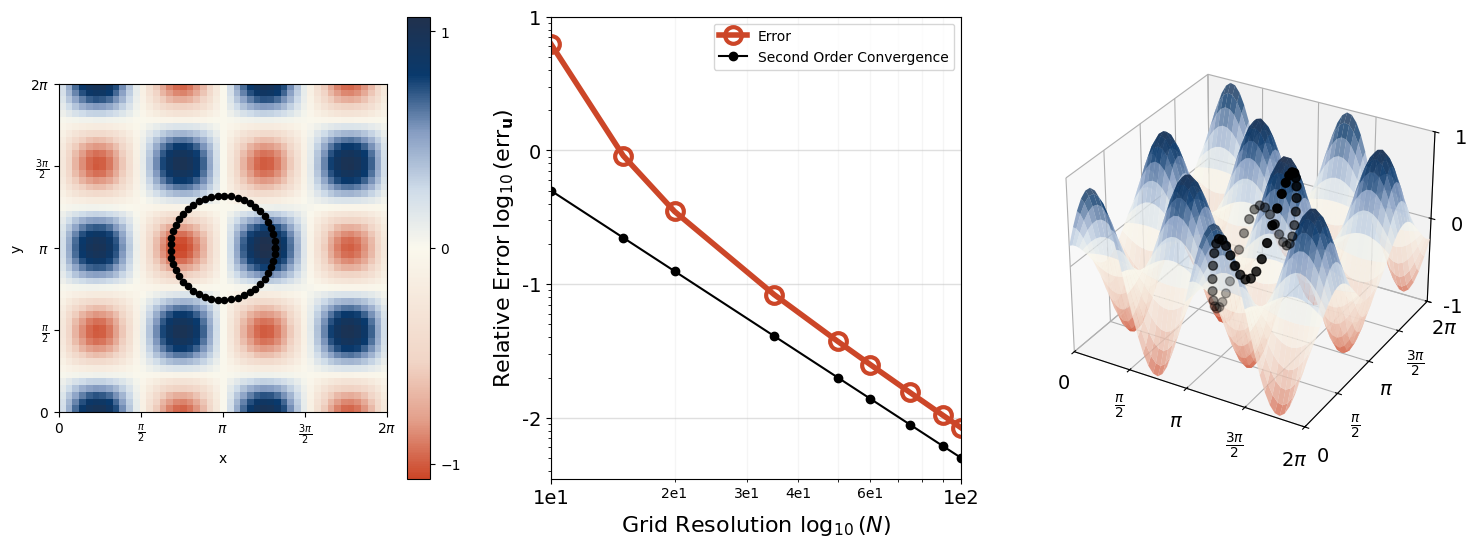

In [ ]:
N = 50

u_approx = solution[:(N-1)**2]

X, Y = np.meshgrid(np.linspace(a, b, N-1), np.linspace(a, b, N-1), indexing='ij')

xy_ticks = np.arange(0, 2*np.pi + 0.01, np.pi/2)
xy_labels = [
    r'$0$',
    r'$\frac{\pi}{2}$',
    r'$\pi$',
    r'$\frac{3\pi}{2}$',
    r'$2\pi$'
]

fig = plt.figure(figsize=(18, 6))

ax = [
    fig.add_subplot(1, 3, 1),
    fig.add_subplot(1, 3, 2),
    fig.add_subplot(1, 3, 3, projection='3d')
]



im = ax[0].imshow(u_approx.reshape((N-1, N-1)), extent=(a, b, a, b), origin='lower', cmap=mines_cmap_div)
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_xticks(xy_ticks)
ax[0].set_xticklabels(xy_labels)
ax[0].set_yticks(xy_ticks)
ax[0].set_yticklabels(xy_labels)
cbar = fig.colorbar(im, ax=ax[0])
cbar.set_ticks([-1, 0, 1])
ax[0].scatter(x_ib_vals[0,:], x_ib_vals[1,:], color='black', s=20, label='IB Points')
# plt.savefig('u_approx_ib.pdf')
# plt.show()

# N_vals = [10, 15, 20, 35, 50, 60, 75, 90, 100]
# errors = []
# Order_2 = [(1 / N**2) * 50 for N in N_vals]

# for N in N_vals:
#     z_approx, info = test_ib(u,u, N, a, b, f, x_ib_vals, reg_var)
#     u_approx = z_approx[:(N-1)**2]
#     u_exact = get_exact(N, a, b, u)
#     errors.append(np.linalg.norm(u_approx - u_exact) / np.linalg.norm(u_exact))

ax[1].loglog(N_vals, errors, marker='o', color=colorado_red, linewidth=4, markersize=12, markeredgewidth=3, markerfacecolor='none', label='Error')
ax[1].loglog(N_vals, Order_2, marker='o', color='black', label='Second Order Convergence')
ax[1].legend()
ax[1].set_ylabel(r"Relative Error $\log_{10}(\text{err}_\mathbf{u})$", fontsize=16)
ax[1].set_xlabel(r"Grid Resolution $\log_{10}(N)$", fontsize=16)
ax[1].set_xlim([min(N_vals), max(N_vals)])
ax[1].grid(True, which="major", linewidth=1, alpha=0.5, color='silver')
ax[1].grid(True, which="minor", linewidth=1, alpha=0.15, color='silver')
ax[1].grid(False, axis="y", which="minor")
ax[1].set_xticks([10, 100])
ax[1].set_xticklabels(['1e1', '1e2'], fontsize=14)
ax[1].set_yticks([10, 1, 1e-1, 1e-2])
ax[1].set_yticklabels(['1', '0', '-1', '-2'], fontsize=14)
ax[1].set_xticks([20, 30, 40, 50, 60, 70, 80, 90], minor=True)
ax[1].set_xticklabels(['2e1', '3e1', '4e1', '', '6e1', '', '', ''], minor=True)

ax[2].computed_zorder = False

ax[2].plot_surface(
    Y, X, u_approx.reshape((N-1, N-1)), cmap=mines_cmap_div, alpha=0.8, zorder=1
)
ax[2].scatter3D(x_ib_vals[1,:], x_ib_vals[0,:],u_ib, color='black', s=40, label='IB Points', zorder=10)

ax[2].set_xlim(a,b)
ax[2].set_ylim(a,b)
ax[2].set_zlim(-1, 1)
ax[2].set_xticks(xy_ticks)
ax[2].set_xticklabels(xy_labels)
ax[2].set_yticks(xy_ticks)
ax[2].set_yticklabels(xy_labels)
ax[2].tick_params(axis='both', labelsize=14)
ax[2].set_zticks([-1, 0, 1])
ax[2].set_zticklabels(['-1', '0', '1'])
# plt.savefig('HW2_ib_complete_1.pdf')
plt.show()

**3. An almost minimal surface**

Now we solve a problem we don't know the answer to:

$$\begin{aligned}
\nabla ^2 u = \mathcal{S}^{ib} q, \\
u(0,y) = u(2\pi, y) = u(x, 0) = u(x, 2\pi) = 0, \\
u(x^{ib}, y^{ib}) = \cos(2x^{ib})\sin(2y^{ib}), \\
x^{ib} = \pi + \cos\theta, \quad y^{ib} = \pi + \sin\theta, \quad \theta \in [0, 2\pi ].
\end{aligned}$$

C:\Users\cjgir\AppData\Local\Temp\ipykernel_23068\4031812120.py:6: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  return np.row_stack((lnspc, lnspc))


(2, 50)
[4.14159265 4.13338267 4.10888752 4.06850941 4.01291136 3.94300628
 3.859942   3.76508246 3.65998522 3.546376   3.42612024 3.30119255
 3.17364423 3.04556963 2.91907172 2.7962276  2.67905436 2.56947599
 2.46929176 2.3801467  2.30350455 2.24062379 2.19253691 2.1600335
 2.14364726 2.14364726 2.1600335  2.19253691 2.24062379 2.30350455
 2.3801467  2.46929176 2.56947599 2.67905436 2.7962276  2.91907172
 3.04556963 3.17364423 3.30119255 3.42612024 3.546376   3.65998522
 3.76508246 3.859942   3.94300628 4.01291136 4.06850941 4.10888752
 4.13338267 4.14159265]


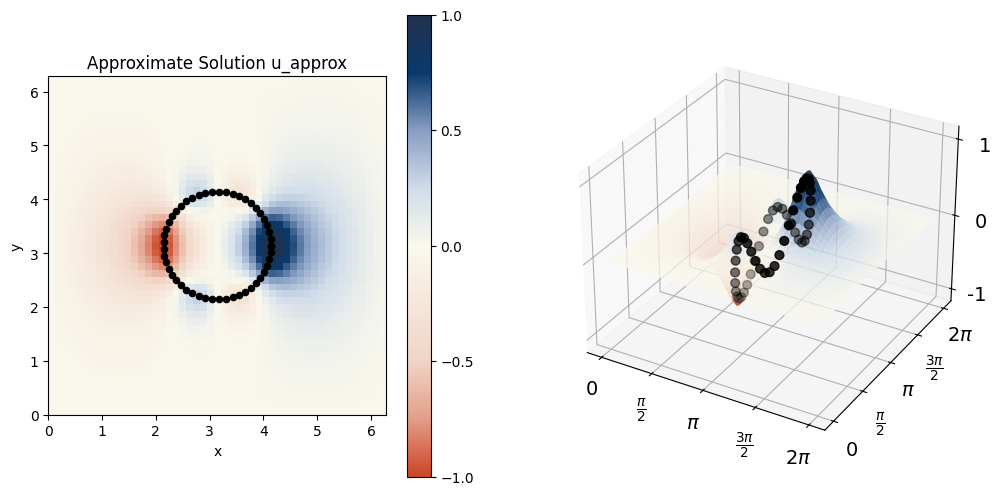

In [152]:
def u_intbdy(x):
    return np.cos(2*x[0]) * np.sin(2*x[1])

def f(x):
    return 0

def u(x):
    return 0

N = 50
N_ib = 50
a = 0
b = np.pi * 2
h = (b-a) / N
reg_var = 1.2
a_th = 0
b_th = np.pi * 2

x_vals = make_grid(a, b, N)
x_ib_vals = get_boundary_points(a_th, b_th, N_ib, x_param, y_param)

print(x_ib_vals.shape)

print(x_ib_vals[0])

solution, info = test_ib(u, u_intbdy, N, a, b, f, x_ib_vals, reg_var)

u_approx = solution[:(N-1)**2]

fig = plt.figure(figsize=(12, 6))
ax = [
    fig.add_subplot(1, 2, 1),
    fig.add_subplot(1, 2, 2, projection='3d')
]

im = ax[0].imshow(u_approx.reshape((N-1, N-1)), extent=(a, b, a, b), origin='lower', cmap=mines_cmap_div, vmin=-1, vmax=1)
cbar = fig.colorbar(im, ax=ax[0])
cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('Approximate Solution u_approx')
ax[0].scatter(x_ib_vals[0,:], x_ib_vals[1,:], color='black', s=20, label='IB Points')

ax[1].computed_zorder = False

ax[1].plot_surface(Y, X, u_approx.reshape((N-1, N-1)), cmap=mines_cmap_div, alpha=0.8, zorder=1)
ax[1].set_zlabel('u_approx')
ax[1].set_xticks(xy_ticks)
ax[1].set_xticklabels(xy_labels)
ax[1].set_yticks(xy_ticks)
ax[1].set_yticklabels(xy_labels)
ax[1].tick_params(axis='both', labelsize=14)
ax[1].set_zticks([-1, 0, 1])
ax[1].set_zticklabels(['-1', '0', '1'])
ax[1].scatter3D(x_ib_vals[1,:], x_ib_vals[0,:],u_ib, color='black', s=40, label='IB Points', zorder=10)
plt.savefig('u_minimal_surface.pdf', bbox_inches='tight')
plt.show()
